# Máxima Verosimilitud (MV) en series de tiempo — Ejercicios bonus

**Ejercicio 1.** Estimación por MV de un **AR(1)** con y sin intercepto cuando el ruido es **Laplace** (no normal). Conexión con la regresión **LAD**.

**Ejercicio 2.** Estimación por MV de un **MA(1)** con ruido normal, resolviendo las condiciones de primer orden **numéricamente con Newton-Raphson**.

---

### Contenido
1. Preparación y funciones auxiliares
2. **Parte 1 — AR(1) con errores Laplace**
   - 2.1 Laplace vs. Normal
   - 2.2 Verosimilitud y condiciones de primer orden (con y sin intercepto)
   - 2.3 ¿Solución cerrada o no?
   - 2.4 Métodos de solución (mediana ponderada, programación lineal, IRLS)
   - 2.5 Comparación con MV-Normal (MCO)
   - 2.6 La función objetivo vista de cerca
   - 2.7 Monte Carlo: ¿quién es más eficiente?
   - 2.8 Regresión LAD y conexión con el AR(1)-Laplace
   - 2.9 Aplicaciones de la Laplace
3. **Parte 2 — MA(1) con Newton-Raphson**
   - 3.1 Modelo y verosimilitud condicional
   - 3.2 El problema de la recursividad
   - 3.3 Newton-Raphson
   - 3.4 Implementación y verificación
   - 3.5 Sensibilidad al valor inicial
   - 3.6 Monte Carlo
4. Conclusiones

## 1. Preparación

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats

rng  = np.random.default_rng(2026)         # Parte 1 (semilla fija -> reproducible)
rng2 = np.random.default_rng(123)          # Parte 2 (generador independiente de la Parte 1)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=5, suppress=True)

# 2. Parte 1 — AR(1) con errores Laplace

## 2.1 Laplace vs. Normal

Una variable $\varepsilon \sim \text{Laplace}(0,b)$ tiene densidad

$$f(\varepsilon)=\frac{1}{2b}\exp\!\left(-\frac{|\varepsilon|}{b}\right),\qquad E[\varepsilon]=0,\quad \text{Var}(\varepsilon)=2b^2 .$$

La Normal tiene $f(\varepsilon)=\frac{1}{\sqrt{2\pi}\sigma}\exp\!\left(-\frac{\varepsilon^2}{2\sigma^2}\right)$.

| | Normal | Laplace |
|---|---|---|
| Exponente | $-\varepsilon^2/(2\sigma^2)$ (cuadrático) | $-\lvert\varepsilon\rvert/b$ (valor absoluto) |
| Forma en el centro | suave (derivable) | **pico** en 0 (no derivable) |
| Colas | ligeras | **más pesadas** (decaimiento exponencial) |
| Curtosis en exceso | 0 | **3** |
| Estimador MV de localización | **media** | **mediana** |
| "Pérdida" que induce | $\varepsilon^2$ (MCO) | $\lvert\varepsilon\rvert$ (LAD) |

Para comparar de forma justa, ambas se dibujan con **varianza 1** ($b=1/\sqrt2$).

Laplace: media=0.00  varianza=1.00  asimetría=0.00  curtosis en exceso=3.00
P(|X|>4)  Normal = 6.33e-05   Laplace = 3.49e-03


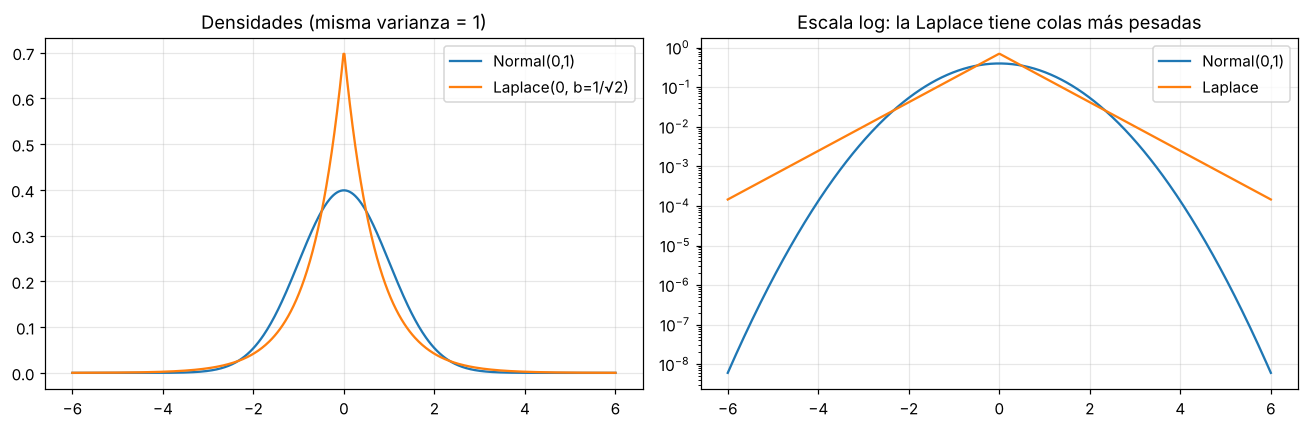

In [2]:
b_lap = 1/np.sqrt(2)                       # Var = 2 b^2 = 1
x = np.linspace(-6, 6, 600)
f_norm = stats.norm.pdf(x, 0, 1)
f_lap  = stats.laplace.pdf(x, 0, b_lap)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x, f_norm, label="Normal(0,1)")
ax[0].plot(x, f_lap,  label="Laplace(0, b=1/√2)")
ax[0].set_title("Densidades (misma varianza = 1)"); ax[0].legend()

ax[1].semilogy(x, f_norm, label="Normal(0,1)")
ax[1].semilogy(x, f_lap,  label="Laplace")
ax[1].set_title("Escala log: la Laplace tiene colas más pesadas"); ax[1].legend()
plt.tight_layout(); plt.show()

m, v, s, k = stats.laplace.stats(scale=b_lap, moments="mvsk")
print(f"Laplace: media={m:.2f}  varianza={v:.2f}  asimetría={s:.2f}  curtosis en exceso={k:.2f}")
print(f"P(|X|>4)  Normal = {2*stats.norm.sf(4):.2e}   Laplace = {2*stats.laplace.sf(4, scale=b_lap):.2e}")

## 2.2 Verosimilitud y condiciones de primer orden

**Modelo con intercepto:**  $y_t = c + \phi\,y_{t-1} + \varepsilon_t,\quad \varepsilon_t \overset{iid}{\sim}\text{Laplace}(0,b)$

**Modelo sin intercepto:** lo mismo con $c=0$.

Trabajamos con la verosimilitud **condicional** a la primera observación $y_0$ (igual que en el caso normal), con $t=1,\dots,T$ y $e_t(c,\phi)=y_t-c-\phi y_{t-1}$:

$$\ell(c,\phi,b)= -T\ln(2b)\;-\;\frac1b\sum_{t=1}^{T}\bigl|\,y_t-c-\phi y_{t-1}\bigr| .$$

**Derivadas** (usando $\frac{d|u|}{du}=\operatorname{sign}(u)$):

$$\frac{\partial \ell}{\partial c}=\frac1b\sum_{t=1}^T \operatorname{sign}(e_t)=0,\qquad
\frac{\partial \ell}{\partial \phi}=\frac1b\sum_{t=1}^T \operatorname{sign}(e_t)\,y_{t-1}=0,\qquad
\frac{\partial \ell}{\partial b}=-\frac Tb+\frac1{b^2}\sum_{t=1}^T |e_t|=0 .$$

De la última se obtiene **en forma cerrada**, dado $(\hat c,\hat\phi)$:

$$\boxed{\hat b=\frac1T\sum_{t=1}^T|\hat e_t|}$$

Y sustituyendo, la verosimilitud concentrada es $\ell^*=-T\ln(2\hat b)-T$, que se maximiza **minimizando $\sum|e_t|$**. 
**Maximizar la verosimilitud Laplace = minimizar la suma de errores absolutos (LAD).**

### Sistema de primer orden

| Modelo | Condiciones de primer orden |
|---|---|
| **Con intercepto** | $\sum \operatorname{sign}(e_t)=0$  y  $\sum \operatorname{sign}(e_t)\,y_{t-1}=0$ |
| **Sin intercepto** | $\sum \operatorname{sign}(y_t-\phi y_{t-1})\,y_{t-1}=0$ |

Interpretación: con intercepto, el residuo mediano debe ser 0 (mitad positivos, mitad negativos); además los residuos no deben tener "correlación de signo" con $y_{t-1}$.

> **Ojo:** $|u|$ **no es derivable en 0**. Las condiciones anteriores son condiciones de *subgradiente*; en el óptimo siempre hay algunos residuos exactamente iguales a 0 (lo comprobamos numéricamente más abajo).

### Contraste con la Normal (MV = MCO)

Con ruido normal las condiciones son **lineales** en $(c,\phi)$ y tienen solución explícita:

- Sin intercepto: $\hat\phi=\dfrac{\sum y_t y_{t-1}}{\sum y_{t-1}^2}$
- Con intercepto: $\hat\phi=\dfrac{\sum (y_t-\bar y_1)(y_{t-1}-\bar y_0)}{\sum (y_{t-1}-\bar y_0)^2},\quad \hat c=\bar y_1-\hat\phi\,\bar y_0$

## 2.3 ¿Cuál tiene solución cerrada y cuál no?

| | Normal | Laplace |
|---|---|---|
| **Sin intercepto** | Cerrada (fórmula lineal) | **No hay fórmula tipo MCO**, pero se reduce a un problema de **una dimensión** con solución *exacta y finita*: $\hat\phi$ es la **mediana ponderada** de los cocientes $y_t/y_{t-1}$ con pesos $\lvert y_{t-1}\rvert$. |
| **Con intercepto** | Cerrada (fórmula lineal) | **No tiene solución cerrada.** Hay que resolver un problema de **programación lineal** (o un algoritmo iterativo como IRLS). |

**Por qué la mediana ponderada (sin intercepto):** como $y_t-\phi y_{t-1}=y_{t-1}\,(r_t-\phi)$ con $r_t=y_t/y_{t-1}$,

$$\sum_t|y_t-\phi y_{t-1}|=\sum_t |y_{t-1}|\;|r_t-\phi| ,$$

y el minimizador de una suma ponderada de desviaciones absolutas es la mediana ponderada de los $r_t$. Equivalentemente, la condición $\sum \operatorname{sign}(y_t-\phi y_{t-1})\,y_{t-1}=0$ se reescribe $\sum |y_{t-1}|\operatorname{sign}(r_t-\phi)=0$.

> Esto es "cerrado" solo en el sentido de que se calcula ordenando y acumulando pesos, sin iterar; **no hay una expresión algebraica** como la de MCO. Con intercepto, no existe una reducción así de simple.

## 2.4 Métodos de solución

Implementamos **tres métodos** y los comparamos:

1. **Mediana ponderada** (solo sin intercepto): exacto.
2. **Programación lineal (LP)**: se escribe $e_t=u_t-v_t$ con $u_t,v_t\ge0$ y se minimiza $\sum(u_t+v_t)$ sujeto a $y_t=c+\phi y_{t-1}+u_t-v_t$. Es exacto (vértice del politopo).
3. **IRLS** (*Iteratively Reweighted Least Squares*): como $|e|=e^2/|e|$, se resuelven MCO ponderados con pesos $w_t=1/|e_t|$ y se itera.

Como verificación extra se usa **Nelder-Mead** sobre la log-verosimilitud.

In [3]:
# ---------- Simulación ----------
def simular_ar1_laplace(T, c, phi, b, rng, burn=200):
    # y_t = c + phi*y_{t-1} + e_t,  e_t ~ Laplace(0,b). Devuelve T+1 obs (y_0,...,y_T).
    e = rng.laplace(0.0, b, T + burn + 1)
    y = np.zeros(T + burn + 1)
    for t in range(1, T + burn + 1):
        y[t] = c + phi * y[t-1] + e[t]
    return y[burn:]

# ---------- MV-Normal (MCO) ----------
def mco_ar1(y, intercepto=True):
    yt, yl = y[1:], y[:-1]
    if intercepto:
        X = np.column_stack([np.ones_like(yl), yl])
        return np.linalg.lstsq(X, yt, rcond=None)[0]        # [c, phi]
    return np.array([0.0, (yl @ yt) / (yl @ yl)])

# ---------- MV-Laplace ----------
def mediana_ponderada(valores, pesos):
    idx = np.argsort(valores)
    v, w = valores[idx], pesos[idx]
    acum = np.cumsum(w)
    return v[np.searchsorted(acum, 0.5 * acum[-1])]

def lad_sin_intercepto(y):
    # phi_hat = mediana ponderada de r_t = y_t/y_{t-1} con pesos |y_{t-1}|
    yt, yl = y[1:], y[:-1]
    m = yl != 0
    return np.array([0.0, mediana_ponderada(yt[m] / yl[m], np.abs(yl[m]))])

def lad_lp(y, intercepto=True):
    # LAD como programa lineal:  min sum(u+v)  s.a.  X b + u - v = y
    yt, yl = y[1:], y[:-1]
    n = len(yt)
    X = np.column_stack([np.ones(n), yl]) if intercepto else yl.reshape(-1, 1)
    p = X.shape[1]
    cost = np.r_[np.zeros(p), np.ones(2 * n)]
    A_eq = np.hstack([X, np.eye(n), -np.eye(n)])
    bounds = [(None, None)] * p + [(0, None)] * (2 * n)
    sol = optimize.linprog(cost, A_eq=A_eq, b_eq=yt, bounds=bounds, method="highs")
    beta = sol.x[:p]
    return beta if intercepto else np.array([0.0, beta[0]])

def lad_irls(y, intercepto=True, iters=500, tol=1e-12, delta=1e-10):
    yt, yl = y[1:], y[:-1]
    X = np.column_stack([np.ones_like(yl), yl]) if intercepto else yl.reshape(-1, 1)
    beta = np.linalg.lstsq(X, yt, rcond=None)[0]             # arranque: MCO
    for k in range(iters):
        r = yt - X @ beta
        w = 1.0 / np.maximum(np.abs(r), delta)               # pesos 1/|e|
        XtW = X.T * w
        beta_new = np.linalg.solve(XtW @ X, XtW @ yt)
        if np.max(np.abs(beta_new - beta)) < tol:
            beta = beta_new; break
        beta = beta_new
    return beta if intercepto else np.array([0.0, beta[0]])

# ---------- Log-verosimilitud Laplace (concentrada en b) ----------
def loglik_laplace(c, phi, y):
    e = y[1:] - c - phi * y[:-1]
    T = len(e)
    b_hat = np.mean(np.abs(e))
    return -T * np.log(2 * b_hat) - T, b_hat

def nelder_mead_laplace(y, intercepto=True):
    if intercepto:
        f = lambda th: -loglik_laplace(th[0], th[1], y)[0]
        r = optimize.minimize(f, mco_ar1(y, True), method="Nelder-Mead",
                              options={"xatol": 1e-10, "fatol": 1e-12, "maxiter": 5000})
        return r.x
    f = lambda th: -loglik_laplace(0.0, th[0], y)[0]
    r = optimize.minimize(f, [mco_ar1(y, False)[1]], method="Nelder-Mead",
                          options={"xatol": 1e-10, "fatol": 1e-12})
    return np.array([0.0, r.x[0]])

## 2.5 Comparación: MV-Laplace vs. MV-Normal (MCO), con y sin intercepto

Simulamos un AR(1) con errores Laplace y comparamos los estimadores.

In [4]:
T, phi_v, b_v = 400, 0.7, 1.0

# ---- Caso A: SIN intercepto (c = 0) ----
yA = simular_ar1_laplace(T, c=0.0, phi=phi_v, b=b_v, rng=rng)
resA = pd.DataFrame({
    "MCO (Normal)":                mco_ar1(yA, False),
    "LAD - mediana ponderada":     lad_sin_intercepto(yA),
    "LAD - programación lineal":   lad_lp(yA, False),
    "LAD - IRLS":                  lad_irls(yA, False),
    "LAD - Nelder-Mead":           nelder_mead_laplace(yA, False),
}, index=["c", "phi"]).T
print("SIN intercepto — verdadero: c=0, phi=0.7")
display(resA)

# ---- Caso B: CON intercepto (c = 2) ----
yB = simular_ar1_laplace(T, c=2.0, phi=phi_v, b=b_v, rng=rng)
resB = pd.DataFrame({
    "MCO (Normal)":                mco_ar1(yB, True),
    "LAD - programación lineal":   lad_lp(yB, True),
    "LAD - IRLS":                  lad_irls(yB, True),
    "LAD - Nelder-Mead":           nelder_mead_laplace(yB, True),
}, index=["c", "phi"]).T
print("\nCON intercepto — verdadero: c=2, phi=0.7")
display(resB)

SIN intercepto — verdadero: c=0, phi=0.7


,c,phi
MCO (Normal),0.0,0.716083
LAD - mediana ponderada,0.0,0.709438
LAD - programación lineal,0.0,0.709438
LAD - IRLS,0.0,0.709438
LAD - Nelder-Mead,0.0,0.709438



CON intercepto — verdadero: c=2, phi=0.7


,c,phi
MCO (Normal),2.246125,0.662466
LAD - programación lineal,2.362768,0.647332
LAD - IRLS,2.362768,0.647332
LAD - Nelder-Mead,2.362768,0.647332


In [5]:
# Estimador de b, log-verosimilitud y número de residuos EXACTAMENTE cero en el óptimo LAD
for nombre, y, interc in [("Sin intercepto", yA, False), ("Con intercepto", yB, True)]:
    c_hat, phi_hat = lad_lp(y, interc)
    ll, b_hat = loglik_laplace(c_hat, phi_hat, y)
    e = y[1:] - c_hat - phi_hat * y[:-1]
    ceros = int(np.sum(np.abs(e) < 1e-8))
    print(f"{nombre:15s} | c_hat={c_hat:7.4f} phi_hat={phi_hat:7.4f} b_hat={b_hat:6.4f} "
          f"loglik={ll:9.3f} | residuos = 0: {ceros}  (nº de parámetros de (c,phi): {2 if interc else 1})")

# Condición de primer orden (subgradiente): sum sign(e) ~ 0 y sum sign(e)*y_{t-1} ~ 0
c_hat, phi_hat = lad_lp(yB, True)
e = yB[1:] - c_hat - phi_hat * yB[:-1]
mask = np.abs(e) > 1e-8
print("\nCon intercepto -> sum sign(e) =", np.sum(np.sign(e[mask])),
      "| sum sign(e)*y_{t-1} =", round(np.sum(np.sign(e[mask]) * yB[:-1][mask]), 4),
      "(los residuos nulos absorben el 'sobrante')")

Sin intercepto  | c_hat= 0.0000 phi_hat= 0.7094 b_hat=0.9968 loglik= -675.979 | residuos = 0: 1  (nº de parámetros de (c,phi): 1)
Con intercepto  | c_hat= 2.3628 phi_hat= 0.6473 b_hat=0.9939 loglik= -674.829 | residuos = 0: 2  (nº de parámetros de (c,phi): 2)

Con intercepto -> sum sign(e) = 0.0 | sum sign(e)*y_{t-1} = 0.7671 (los residuos nulos absorben el 'sobrante')


**Observaciones clave**

- Con ruido Laplace, MCO y LAD dan estimaciones parecidas pero **no iguales**; LAD es el estimador de máxima verosimilitud, así que es el eficiente.
- En el óptimo LAD **hay exactamente tantos residuos iguales a cero como parámetros** del modelo (1 sin intercepto, 2 con intercepto): la recta "interpola" esos puntos. Es la firma de un vértice de programación lineal y la razón por la que no hay fórmula derivable.
- La mediana ponderada, la LP, IRLS y Nelder-Mead coinciden (salvo tolerancia numérica).

## 2.6 La función objetivo vista de cerca (sin intercepto)

$S(\phi)=\sum_t|y_t-\phi y_{t-1}|$ es **convexa y lineal a trozos**, con "quiebres" en cada $\phi=r_t$. Su mínimo está en un quiebre (la mediana ponderada). En cambio, la suma de cuadrados es una **parábola suave**.

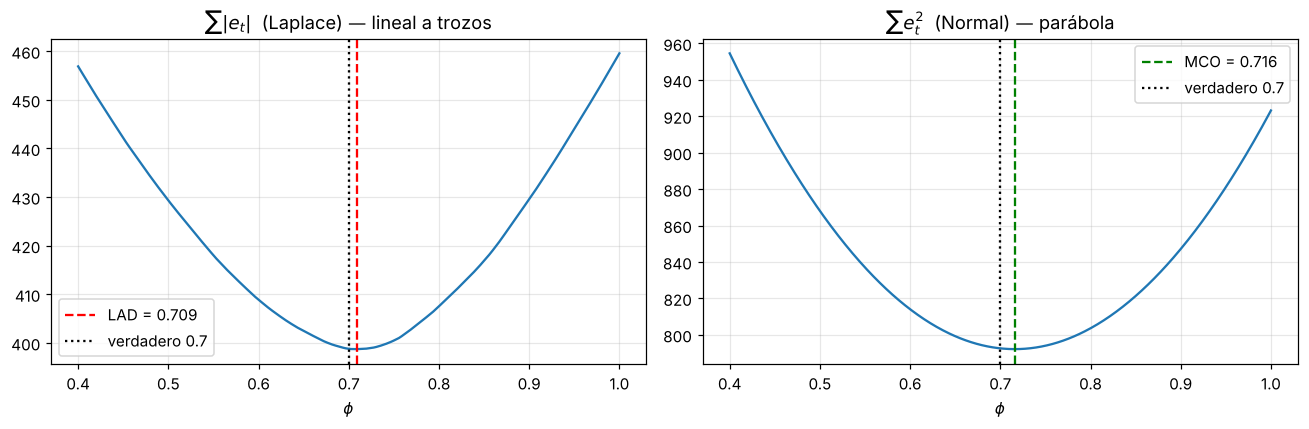

In [6]:
grid = np.linspace(0.4, 1.0, 600)
yt, yl = yA[1:], yA[:-1]
S_abs = np.array([np.sum(np.abs(yt - g * yl)) for g in grid])
S_sq  = np.array([np.sum((yt - g * yl) ** 2) for g in grid])
phi_lad, phi_mco = lad_sin_intercepto(yA)[1], mco_ar1(yA, False)[1]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(grid, S_abs); ax[0].axvline(phi_lad, color="r", ls="--", label=f"LAD = {phi_lad:.3f}")
ax[0].axvline(0.7, color="k", ls=":", label="verdadero 0.7")
ax[0].set_title(r"$\sum|e_t|$  (Laplace) — lineal a trozos"); ax[0].set_xlabel(r"$\phi$"); ax[0].legend()

ax[1].plot(grid, S_sq); ax[1].axvline(phi_mco, color="g", ls="--", label=f"MCO = {phi_mco:.3f}")
ax[1].axvline(0.7, color="k", ls=":", label="verdadero 0.7")
ax[1].set_title(r"$\sum e_t^2$  (Normal) — parábola"); ax[1].set_xlabel(r"$\phi$"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2.7 Monte Carlo: ¿quién es más eficiente?

Repetimos el experimento muchas veces con errores **Laplace** y con errores **Normales** (ambos con varianza 1).

Teoría asintótica para el AR(1) (con $\gamma_0=\sigma^2/(1-\phi^2)$):

$$\text{Var}(\hat\phi_{MCO})\approx\frac{\sigma^2}{T\gamma_0}=\frac{1-\phi^2}{T},\qquad
\text{Var}(\hat\phi_{LAD})\approx\frac{1}{4f(0)^2}\cdot\frac{1}{T\gamma_0}.$$

- Laplace: $f(0)=\frac1{2b}$ y $\sigma^2=2b^2$ ⇒ $\text{Var}_{LAD}/\text{Var}_{MCO}=\tfrac12$ (LAD **el doble de eficiente**).
- Normal: $f(0)=\frac1{\sqrt{2\pi}\sigma}$ ⇒ razón $=\pi/2\approx1.57$ (MCO es mejor).

,errores,media MCO,sd MCO,media LAD,sd LAD,Var(LAD)/Var(MCO)
0,laplace,0.6899,0.0444,0.6951,0.0351,0.6255
1,normal,0.6887,0.0432,0.6904,0.0533,1.5217


Razón asintótica teórica: Laplace -> 0.50 | Normal -> 1.57  (con T finito la razón de LAD sale algo mayor; baja hacia 0.50 al crecer T — con T=2000 verifiqué ≈0.49)
sd teórica de MCO = sqrt((1-phi^2)/T) = 0.0412


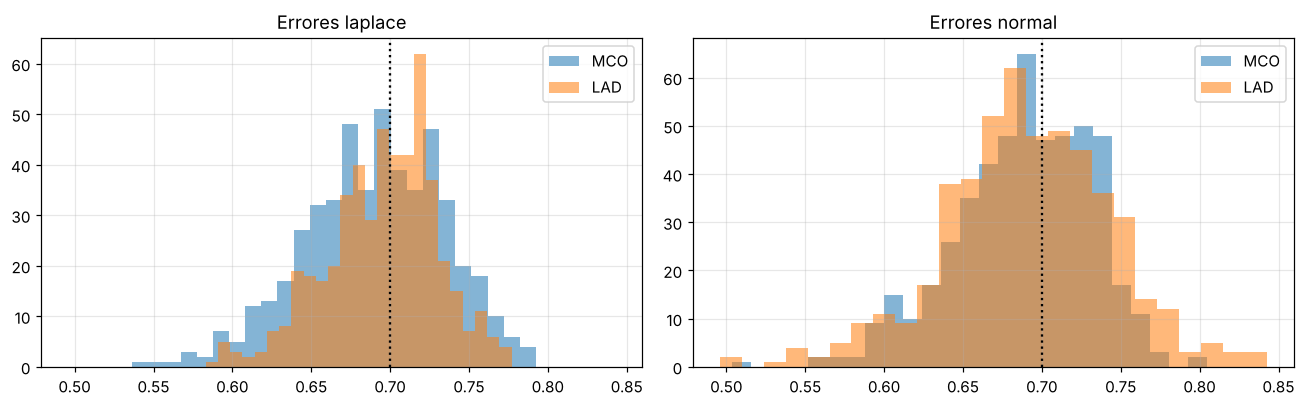

In [7]:
def montecarlo_ar1(reps, T, c, phi, dist, rng):
    est_mco, est_lad = [], []
    for _ in range(reps):
        if dist == "laplace":
            e = rng.laplace(0, 1/np.sqrt(2), T + 301)       # var = 1
        else:
            e = rng.normal(0, 1, T + 301)
        y = np.zeros(T + 301)
        for t in range(1, T + 301):
            y[t] = c + phi * y[t-1] + e[t]
        y = y[300:]
        est_mco.append(mco_ar1(y, True)[1]); est_lad.append(lad_lp(y, True)[1])
    return np.array(est_mco), np.array(est_lad)

reps, T_mc, phi_mc = 500, 300, 0.7
resultados, filas = {}, []
for dist in ["laplace", "normal"]:
    m, l = montecarlo_ar1(reps, T_mc, 1.0, phi_mc, dist, rng)
    resultados[dist] = (m, l)
    filas.append([dist, m.mean(), m.std(), l.mean(), l.std(), (l.var() / m.var())])
mc = pd.DataFrame(filas, columns=["errores", "media MCO", "sd MCO", "media LAD", "sd LAD", "Var(LAD)/Var(MCO)"])
display(mc.round(4))
print("Razón asintótica teórica: Laplace -> 0.50 | Normal -> 1.57  (con T finito la razón de LAD sale algo mayor; baja hacia 0.50 al crecer T — con T=2000 verifiqué ≈0.49)")
print(f"sd teórica de MCO = sqrt((1-phi^2)/T) = {np.sqrt((1-phi_mc**2)/T_mc):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for a, dist in zip(ax, ["laplace", "normal"]):
    m, l = resultados[dist]
    a.hist(m, bins=25, alpha=.55, label="MCO"); a.hist(l, bins=25, alpha=.55, label="LAD")
    a.axvline(phi_mc, color="k", ls=":"); a.set_title(f"Errores {dist}"); a.legend()
plt.tight_layout(); plt.show()

## 2.8 Regresión LAD y conexión con el AR(1) con ruido Laplace

La **regresión LAD** (*Least Absolute Deviations*, o regresión por la **mediana**, un caso de la regresión cuantílica con $\tau=0.5$) estima los coeficientes minimizando

$$\hat\beta_{LAD}=\arg\min_\beta\sum_{i}|y_i-x_i'\beta| \qquad\text{(en lugar de }\textstyle\sum (y_i-x_i'\beta)^2\text{)}.$$

**Conexión:** en el modelo lineal $y_i=x_i'\beta+\varepsilon_i$ con $\varepsilon_i\sim\text{Laplace}(0,b)$, la log-verosimilitud es $-n\ln(2b)-\frac1b\sum|y_i-x_i'\beta|$. Por tanto

$$\boxed{\hat\beta_{MV\text{-}Laplace}=\hat\beta_{LAD}}\qquad\Longleftrightarrow\qquad \text{MCO}\leftrightarrow\text{Normal},\quad \text{LAD}\leftrightarrow\text{Laplace}.$$

El AR(1) es simplemente el caso con $x_t=(1,\,y_{t-1})'$. Por eso, en este notebook, `lad_lp` **es** el estimador MV del AR(1)-Laplace.

**Ventaja práctica:** LAD es **robusto a valores atípicos** (la pérdida crece linealmente, no cuadráticamente). Lo mostramos con un ejemplo.

In [8]:
# Robustez: contaminamos 5 observaciones con "outliers" grandes
y_out = yB.copy()
idx = rng.choice(np.arange(1, len(y_out)), size=5, replace=False)
y_out[idx] += rng.choice([-1, 1], 5) * 25

fila = pd.DataFrame({
    "limpio":        [mco_ar1(yB)[1],    lad_lp(yB)[1]],
    "con outliers":  [mco_ar1(y_out)[1], lad_lp(y_out)[1]],
}, index=["MCO phi_hat", "LAD phi_hat"])
display(fila.round(4))
print("Verdadero phi = 0.7  -> LAD casi no se mueve; MCO sí.")

,limpio,con outliers
MCO phi_hat,0.6625,0.2146
LAD phi_hat,0.6473,0.5098


Verdadero phi = 0.7  -> LAD casi no se mueve; MCO sí.


## 2.9 ¿Qué aplicaciones tiene la distribución Laplace?

- **Finanzas / econometría:** retornos con colas pesadas y pico central (alternativa simple a la Normal); regresión robusta.
- **Estadística robusta:** regresión LAD / cuantílica ante outliers.
- **Privacidad diferencial:** el *mecanismo de Laplace* añade ruido Laplace a consultas para proteger datos individuales.
- **Procesamiento de señales e imágenes:** los gradientes y coeficientes wavelet se modelan bien con Laplace.
- **Aprendizaje automático:** regularización **Lasso** ($L_1$) equivale a una *a priori* Laplace sobre los coeficientes (enfoque bayesiano MAP).
- **Reconocimiento de voz:** distribución de amplitudes de señales de audio.

## Conclusiones de la Parte 1

1. Con ruido Laplace, $\hat\theta_{MV}$ minimiza $\sum|e_t|$ (LAD); $\hat b=\frac1T\sum|\hat e_t|$.
2. **Normal:** ambos modelos (con y sin intercepto) tienen solución cerrada. **Laplace:** sin intercepto se reduce a una **mediana ponderada** (exacta, sin iterar, pero sin fórmula algebraica tipo MCO); con intercepto **no hay solución cerrada** → programación lineal / IRLS.
3. En el óptimo LAD hay tantos residuos cero como parámetros.
4. Con errores Laplace, LAD es ~2 veces más eficiente que MCO; con errores Normales ocurre al revés ($\pi/2$).

# 3. Parte 2 — MA(1) con ruido normal y Newton-Raphson

## 3.1 Modelo y verosimilitud condicional

Modelo (el mismo que se desarrolló en clase):

$$y_t=\varepsilon_t+\beta_1\,\varepsilon_{t-1},\qquad \varepsilon_t\overset{iid}{\sim}N(0,\sigma^2),\qquad |\beta_1|<1\ \text{(invertibilidad)}.$$

Despejando el error: 

$$\varepsilon_t=y_t-\beta_1\varepsilon_{t-1}.$$

Los $\varepsilon_t$ **no se observan**, pero se pueden reconstruir recursivamente si se fija $\varepsilon_0=0$ (**MV condicional**). Entonces

$$\ell(\beta_1,\sigma^2)=-\frac T2\ln(2\pi\sigma^2)-\frac1{2\sigma^2}\sum_{t=1}^T\varepsilon_t(\beta_1)^2 .$$

- Respecto a $\sigma^2$: $\hat\sigma^2=\frac1T\sum\hat\varepsilon_t^2$ (cerrada).
- Respecto a $\beta_1$: maximizar $\ell$ equivale a **minimizar** $S(\beta_1)=\sum\varepsilon_t(\beta_1)^2$. La condición de primer orden es

$$\sum_{t=1}^T \varepsilon_t\,\frac{\partial\varepsilon_t}{\partial\beta_1}=0 .$$

## 3.2 El problema de la recursividad

$\varepsilon_t$ depende de $\beta_1$ **y de $\varepsilon_{t-1}$**, que a su vez depende de $\beta_1$, etc. Por eso la condición de primer orden es **altamente no lineal** en $\beta_1$ (un polinomio de grado $\sim T$) y **no tiene solución analítica**. Las derivadas también son recursivas:

$$\frac{\partial\varepsilon_t}{\partial\beta_1}=-\varepsilon_{t-1}-\beta_1\frac{\partial\varepsilon_{t-1}}{\partial\beta_1},\qquad
\frac{\partial^2\varepsilon_t}{\partial\beta_1^2}=-2\frac{\partial\varepsilon_{t-1}}{\partial\beta_1}-\beta_1\frac{\partial^2\varepsilon_{t-1}}{\partial\beta_1^2},$$

con condiciones iniciales $\varepsilon_0=0,\ \partial\varepsilon_0/\partial\beta_1=0,\ \partial^2\varepsilon_0/\partial\beta_1^2=0$.

## 3.3 Newton-Raphson

Se quiere resolver $g(\beta)=0$ con

$$g(\beta)=\sum_t\varepsilon_t\varepsilon_t',\qquad 
H(\beta)=g'(\beta)=\underbrace{\sum_t\left(\varepsilon_t'\right)^2}_{>0}+\sum_t\varepsilon_t\,\varepsilon_t'' \quad\text{(la SOC vista en clase)},$$

donde $\varepsilon_t'=\partial\varepsilon_t/\partial\beta_1$ y $\varepsilon_t''=\partial^2\varepsilon_t/\partial\beta_1^2$. La iteración es

$$\boxed{\beta^{(k+1)}=\beta^{(k)}-\frac{g(\beta^{(k)})}{H(\beta^{(k)})}}$$

**Detalles:**
- $\partial\ell/\partial\beta_1=-g/\sigma^2$ y $\partial^2\ell/\partial\beta_1^2=-H/\sigma^2$: el factor $\sigma^2$ **se cancela** en el cociente, por eso la iteración no depende de $\sigma^2$.
- En el mínimo de $S$ se necesita $H>0$ (condición de segundo orden).
- Errores estándar: $\widehat{\text{Var}}(\hat\beta_1)=\hat\sigma^2/H(\hat\beta_1)$, que se compara con el valor asintótico teórico $(1-\beta_1^2)/T$.

In [9]:
def recursion_ma1(beta, y):
    # Devuelve e_t, de_t/dbeta, d2e_t/dbeta2 para t=1..T con e_0 = 0.
    T = len(y)
    e, d1, d2 = np.zeros(T), np.zeros(T), np.zeros(T)
    e_p = d1_p = d2_p = 0.0                      # condiciones iniciales (t=0)
    for t in range(T):
        e[t]  = y[t] - beta * e_p                # e_t  = y_t - beta*e_{t-1}
        d1[t] = -e_p - beta * d1_p               # e'_t = -e_{t-1} - beta*e'_{t-1}
        d2[t] = -2.0 * d1_p - beta * d2_p        # e''_t = -2 e'_{t-1} - beta e''_{t-1}
        e_p, d1_p, d2_p = e[t], d1[t], d2[t]
    return e, d1, d2

def S_g_H(beta, y):
    e, d1, d2 = recursion_ma1(beta, y)
    S = e @ e                                    # suma de cuadrados
    g = e @ d1                                   # gradiente de S/2
    H = d1 @ d1 + e @ d2                         # hessiano de S/2
    return S, g, H

def loglik_ma1(beta, y):
    # Log-verosimilitud concentrada en sigma^2 (sigma2_hat = S/T)
    T = len(y); S = S_g_H(beta, y)[0]
    return -0.5 * T * (np.log(2 * np.pi) + np.log(S / T) + 1)

def newton_raphson_ma1(y, beta0=0.0, tol=1e-10, max_iter=50, verbose=True):
    beta = beta0
    hist = []
    for k in range(max_iter):
        S, g, H = S_g_H(beta, y)
        hist.append({"iter": k, "beta": beta, "S": S, "gradiente": g, "hessiano": H})
        if abs(g) < tol:
            break
        if H <= 0:
            raise RuntimeError(f"Hessiano no positivo (H={H:.3g}) en beta={beta:.4f}: NR no es confiable aquí.")
        beta_new = beta - g / H                  # paso de Newton-Raphson
        if abs(beta_new) >= 1:                   # fuera de la región de invertibilidad
            beta_new = 0.5 * (beta + np.sign(beta_new))   # recorte simple dentro de (-1,1)
        beta = beta_new
    else:
        print("¡Aviso! No convergió en max_iter")
    S, g, H = S_g_H(beta, y)
    hist.append({"iter": len(hist), "beta": beta, "S": S, "gradiente": g, "hessiano": H})
    return beta, pd.DataFrame(hist)

## 3.4 Implementación y verificación

**Paso 1 — Simular** un MA(1) con $\beta_1=0.6$, $\sigma=1$, $T=500$.

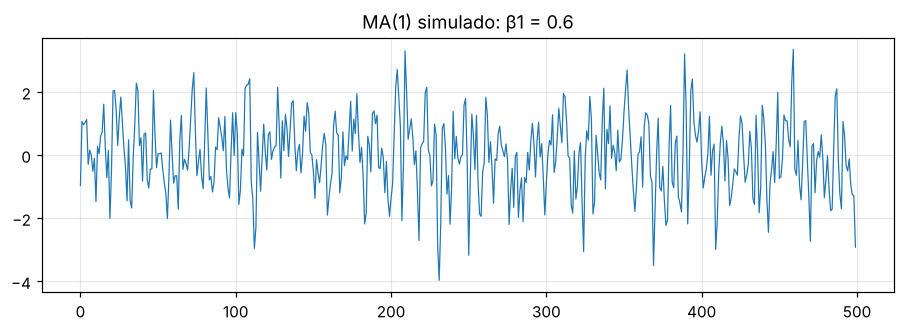

In [10]:
def simular_ma1(T, beta, sigma, rng):
    e = rng.normal(0, sigma, T + 1)
    return e[1:] + beta * e[:-1]                 # y_t = e_t + beta*e_{t-1}

T2, beta_v, sigma_v = 500, 0.6, 1.0
y_ma = simular_ma1(T2, beta_v, sigma_v, rng2)

plt.figure(figsize=(10, 3)); plt.plot(y_ma, lw=.8); plt.title("MA(1) simulado: β1 = 0.6"); plt.show()

**Paso 2 — Verificar las derivadas analíticas** contra diferencias finitas (si esto falla, NR no servirá).

In [11]:
b_test, h = 0.3, 1e-6
S0, g0, H0 = S_g_H(b_test, y_ma)
g_num = (S_g_H(b_test + h, y_ma)[0] - S_g_H(b_test - h, y_ma)[0]) / (2 * h) / 2     # dS/dbeta / 2
H_num = (S_g_H(b_test + h, y_ma)[1] - S_g_H(b_test - h, y_ma)[1]) / (2 * h)         # dg/dbeta
print(f"gradiente  analítico = {g0:.6f} | numérico = {g_num:.6f}")
print(f"hessiano   analítico = {H0:.6f} | numérico = {H_num:.6f}")

gradiente  analítico = -159.977228 | numérico = -159.977228
hessiano   analítico = 419.213912 | numérico = 419.213912


**Paso 3 — Ejecutar Newton-Raphson** desde $\beta^{(0)}=0$.

In [12]:
beta_nr, hist = newton_raphson_ma1(y_ma, beta0=0.0)
display(hist.round(8))

S_f, g_f, H_f = S_g_H(beta_nr, y_ma)
sigma2_hat = S_f / T2
se_hat = np.sqrt(sigma2_hat / H_f)
print(f"\nβ1_hat (Newton-Raphson) = {beta_nr:.6f}")
print(f"σ²_hat = S/T             = {sigma2_hat:.6f}   (verdadero: {sigma_v**2})")
print(f"Error estándar (σ²/H)^½  = {se_hat:.5f}   | teórico sqrt((1-β²)/T) = {np.sqrt((1-beta_v**2)/T2):.5f}")
print(f"IC 95% aprox: [{beta_nr-1.96*se_hat:.4f}, {beta_nr+1.96*se_hat:.4f}]  (verdadero {beta_v})")

,iter,beta,S,gradiente,hessiano
0,0,0.000000,692.888334,-311.089901,653.383510
1,1,0.476121,511.847026,-83.394059,486.970136
2,2,0.647372,500.798529,34.062799,1053.078059
3,3,0.615026,499.619258,3.480813,851.086981
4,4,0.610937,499.604907,0.042063,830.679295
5,5,0.610886,499.604904,0.000006,830.432651
6,6,0.610886,499.604904,0.000000,830.432614
7,7,0.610886,499.604904,0.000000,830.432614



β1_hat (Newton-Raphson) = 0.610886
σ²_hat = S/T             = 0.999210   (verdadero: 1.0)
Error estándar (σ²/H)^½  = 0.03469   | teórico sqrt((1-β²)/T) = 0.03578
IC 95% aprox: [0.5429, 0.6789]  (verdadero 0.6)


**Paso 4 — Validar** con (a) minimización numérica independiente de `scipy` y (b) búsqueda en rejilla. Además, se grafica $S(\beta)$ con las iteraciones de Newton-Raphson.

scipy minimize_scalar : 0.610886
Newton-Raphson        : 0.610886
Rejilla               : 0.611905 (resolución 0.0048)


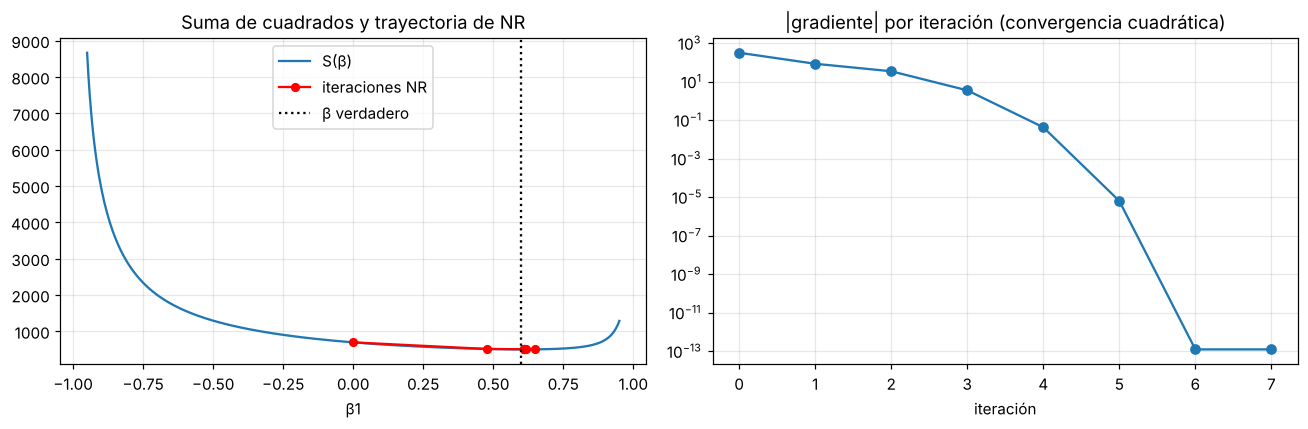

In [13]:
# (a) scipy
res = optimize.minimize_scalar(lambda b: S_g_H(b, y_ma)[0], bounds=(-0.99, 0.99), method="bounded",
                               options={"xatol": 1e-10})
print(f"scipy minimize_scalar : {res.x:.6f}")
print(f"Newton-Raphson        : {beta_nr:.6f}")

# (b) rejilla
grid = np.linspace(-0.95, 0.95, 400)
S_grid = np.array([S_g_H(b, y_ma)[0] for b in grid])
print(f"Rejilla               : {grid[np.argmin(S_grid)]:.6f} (resolución 0.0048)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(grid, S_grid, label="S(β)")
ax[0].plot(hist["beta"], hist["S"], "ro-", ms=5, label="iteraciones NR")
ax[0].axvline(beta_v, color="k", ls=":", label="β verdadero")
ax[0].set_title("Suma de cuadrados y trayectoria de NR"); ax[0].set_xlabel("β1"); ax[0].legend()

ax[1].semilogy(hist["iter"], np.abs(hist["gradiente"]) + 1e-18, "o-")
ax[1].set_title("|gradiente| por iteración (convergencia cuadrática)"); ax[1].set_xlabel("iteración")
plt.tight_layout(); plt.show()

## 3.5 Sensibilidad al valor inicial

Newton-Raphson es muy rápido cerca del óptimo, pero **en general** puede fallar si el arranque es malo (hessiano no positivo, saltos fuera de $|\beta|<1$). En esta muestra converge desde todos los arranques probados, aunque necesita más iteraciones cuando se parte de los extremos (cerca de $\pm1$).

In [14]:
filas = []
for b0 in [-0.9, -0.5, 0.0, 0.3, 0.8, 0.95]:
    try:
        b_hat, h = newton_raphson_ma1(y_ma, beta0=b0)
        filas.append([b0, b_hat, len(h) - 1, "ok"])
    except RuntimeError as err:
        filas.append([b0, np.nan, np.nan, "falló: H<=0"])
display(pd.DataFrame(filas, columns=["β0 inicial", "β̂ final", "iteraciones", "estado"]).round(6))

,β0 inicial,β̂ final,iteraciones,estado
0,-0.90,0.610886,13,ok
1,-0.50,0.610886,8,ok
2,0.00,0.610886,7,ok
3,0.30,0.610886,7,ok
4,0.80,0.610886,7,ok
5,0.95,0.610886,11,ok


## 3.6 Monte Carlo: propiedades del estimador

Repetimos 300 veces y comparamos la media y la desviación estándar de $\hat\beta_1$ con la teoría ($\sqrt{(1-\beta_1^2)/T}$).

réplicas convergidas : 300/300
media de β̂           : 0.6073   (verdadero 0.6)
sd empírica de β̂     : 0.0453
sd teórica           : 0.0462


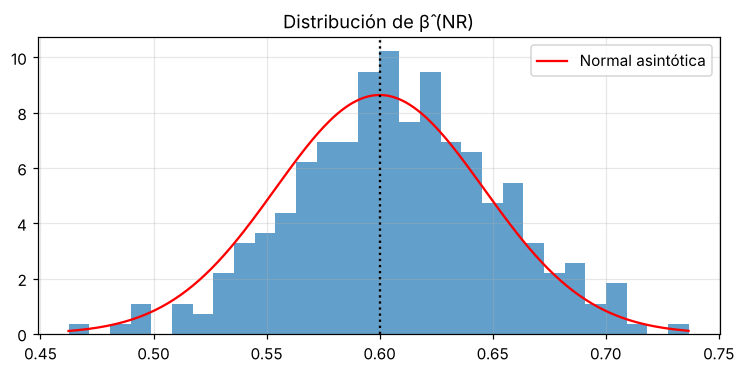

In [15]:
reps, T_mc, b_mc = 300, 300, 0.6
est = []
for _ in range(reps):
    y_s = simular_ma1(T_mc, b_mc, 1.0, rng2)
    try:
        est.append(newton_raphson_ma1(y_s, 0.0)[0])
    except RuntimeError:
        pass
est = np.array(est)
print(f"réplicas convergidas : {len(est)}/{reps}")
print(f"media de β̂           : {est.mean():.4f}   (verdadero {b_mc})")
print(f"sd empírica de β̂     : {est.std():.4f}")
print(f"sd teórica           : {np.sqrt((1-b_mc**2)/T_mc):.4f}")

plt.figure(figsize=(8, 3.5)); plt.hist(est, bins=30, density=True, alpha=.7)
xs = np.linspace(est.min(), est.max(), 200)
plt.plot(xs, stats.norm.pdf(xs, b_mc, np.sqrt((1-b_mc**2)/T_mc)), "r", label="Normal asintótica")
plt.axvline(b_mc, color="k", ls=":"); plt.legend(); plt.title("Distribución de β̂ (NR)"); plt.show()

## Conclusiones de la Parte 2

1. En el MA(1) los errores solo se reconstruyen **recursivamente**, por lo que la condición de primer orden no tiene solución analítica → se usa un método numérico.
2. Con $\varepsilon_0=0$ la MV es **condicional**; maximizar $\ell$ equivale a minimizar $S(\beta_1)=\sum\varepsilon_t^2$.
3. Newton-Raphson: $\beta^{(k+1)}=\beta^{(k)}-g/H$, con $g=\sum\varepsilon_t\varepsilon_t'$ y $H=\sum[(\varepsilon_t')^2+\varepsilon_t\varepsilon_t'']$ calculados por recursión.
4. El método converge en pocas iteraciones, coincide con `scipy` y su error estándar coincide con la teoría asintótica $\sqrt{(1-\beta_1^2)/T}$.

---
## 4. Conclusión general

| Idea | Normal | Laplace |
|---|---|---|
| Función de pérdida inducida | cuadrática | valor absoluto |
| Estimador MV (AR(1)) | MCO (cerrado, con y sin intercepto) | LAD (sin intercepto: mediana ponderada; con intercepto: LP/IRLS) |
| MA(1) | sin cerrada → Newton-Raphson | — |

**Referencias:** Hamilton (1994), *Time Series Analysis*, cap. 5 (MV de ARMA); Koenker (2005), *Quantile Regression*; documentación de `scipy.optimize`.